# Chapter 1: The Lift That Wasn't: Why We Randomise

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [The Lift That Wasn't: Why We Randomise](https://books.sugiv.fyi/lift/lift-that-wasnt.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)

from sim import foundations as F, style

style.apply()
pd.set_option("display.precision", 3)


def glue_num(name, value):
    glue(name, float(value), display=False)


L = F.learners()
O = F.opt_in(L)
g = O.groupby("shield").retained.mean()
glue_num("naive_pts", 100 * (g[1] - g[0]))
glue_num("ate_pts", 100 * (L.y1 - L.y0).mean())
glue_num("opt_share", 100 * O.shield.mean())

Here's the finding first. Parlo launched **Streak Shield**, which protects a learner's streak if they miss a single day. Learners could switch it on in settings, and 34% did. A month later the dashboard was triumphant: learners with Streak Shield were **25 points more likely to still be active** than learners without it.

The feature's real effect was about **1.5 points**. The other twenty-odd points were never the feature's to claim. They came from *who* chose to switch it on: keen learners, who were going to stay anyway.

This chapter is about why that happens, why a coin flip fixes it, and why the honest answer, once you have it, is usually smaller and less certain than anyone hoped. Every later chapter in the book builds on these ideas.

> **Note**
>
> **Parlo** (a language-learning app) and **Juno** (its AI tutor) are fictional. Every number comes from a seeded simulator in `lift/sim/foundations.py`. Because it's a simulator, we get to see something real data never shows: what each learner *would have* done in both worlds.

## Two worlds for every learner

For every learner there are two possible futures:

- **$Y(1)$:** retained at day 30 *if they have* Streak Shield.
- **$Y(0)$:** retained at day 30 *if they don't*.

The feature's effect on that learner is the difference, $Y(1) - Y(0)$. This is the **potential outcomes** framework (Wager, 2026), and it's the cleanest way I know to think about "did it work?".

Here are eight learners in the god view, which only a simulator gives you:

In [3]:
tipped = O.index[(O.y1 - O.y0) == 1][:2]
others = O.index[(O.y1 - O.y0) == 0][:6]
god = O.loc[others.append(tipped), ["keenness", "y0", "y1", "shield", "retained"]].copy()
god.index = [f"learner {i + 1}" for i in range(8)]
god["effect Y(1) - Y(0)"] = god.y1 - god.y0
god.rename(columns={"y0": "Y(0) no shield", "y1": "Y(1) shield",
                    "shield": "chose shield", "retained": "what we see"}).round(2)

,keenness,Y(0) no shield,Y(1) shield,chose shield,what we see,effect Y(1) - Y(0)
learner 1,0.13,1,1,0,1,0
learner 2,-0.13,0,0,0,0,0
learner 3,0.64,0,0,1,0,0
learner 4,0.10,1,1,0,1,0
learner 5,-0.54,0,0,0,0,0
learner 6,0.36,1,1,0,1,0
learner 7,-0.54,0,1,0,0,1
learner 8,-0.67,0,1,0,0,1


Most learners have an effect of zero: they stay, or leave, whichever world they're in. Learners 7 and 8 are different: the shield tips them into staying. Only about one learner in seventy is like that. That's what a small average effect looks like up close.

Now the catch. In real life you only ever see **one** of the two columns per learner, the one matching what they actually did. The other is a counterfactual. It's gone. Every method in this book is a way of estimating the missing column, and the methods differ only in what they assume to fill it in.

## Why the naive comparison lies

The dashboard compares learners who chose the shield with learners who didn't. Here's what that difference is made of. Let $T = 1$ mean "has the shield":

$$
\underbrace{E[Y \mid T{=}1] - E[Y \mid T{=}0]}_{\text{what the dashboard shows}}
= \underbrace{E[Y(1) - Y(0) \mid T{=}1]}_{\text{effect on those who chose it}}
+ \underbrace{E[Y(0) \mid T{=}1] - E[Y(0) \mid T{=}0]}_{\text{selection bias}}
$$

The second term asks: *without the shield*, would the people who chose it have retained differently from the people who didn't? Here, very much so. Because we have both columns, we can measure each piece:

In [4]:
chose = O.shield == 1
effect_on_choosers = (O.y1 - O.y0)[chose].mean()
selection_bias = O.y0[chose].mean() - O.y0[~chose].mean()
pd.Series({
    "dashboard difference": O.retained[chose].mean() - O.retained[~chose].mean(),
    "  = effect on those who chose it": effect_on_choosers,
    "  + selection bias": selection_bias,
}).mul(100).round(1).to_frame("points")

,points
dashboard difference,24.6
= effect on those who chose it,1.6
+ selection bias,23.0


Nearly the whole number is selection bias. The learners who switched Streak Shield on were keener to begin with. They also did more lessons in their first week, before the shield existed for them:

In [5]:
O.groupby(O.shield.map({0: "no shield", 1: "chose shield"}))[["keenness", "lessons_wk1"]].mean().round(2)

,keenness,lessons_wk1
shield,,
chose shield,0.74,5.2
no shield,-0.37,3.0


You might hope statistics rescues you here. It doesn't. A t-test on the dashboard comparison is wildly "significant":

In [6]:
naive = pg.ttest(O.retained[chose], O.retained[~chose])
naive[["T", "p_val", "cohen_d"]]

,T,p_val,cohen_d
T_test,33.866,9.007e-241,0.519


That p-value says the gap is very unlikely to be noise. That's true! The gap is real. It just isn't caused by the feature. **Significance tells you a difference is unlikely to be chance; it says nothing about what caused it.**

## The coin flip

Now suppose that instead of letting learners choose, Parlo flips a coin for each one: heads, you get Streak Shield; tails, you don't. Keenness can't influence a coin. So the two groups are alike, on average, in *everything*: keenness, first-week lessons, time zone, mood, and every other thing we never thought to measure. The selection bias term becomes zero, and the simple difference in means estimates the average effect.

In [7]:
R = F.randomise(L)
heads = R.shield == 1
R.groupby(R.shield.map({0: "control", 1: "shield"}))[["keenness", "lessons_wk1"]].mean().round(2)

,keenness,lessons_wk1
shield,,
control,-0.00,3.74
shield,0.01,3.74


The groups are balanced, and we didn't have to know which variables mattered. That's the real power of randomisation: it balances what you *didn't* measure, too.

Here's the readout with Pingouin:

In [8]:
res = pg.ttest(R.retained[heads], R.retained[~heads])
diff = R.retained[heads].mean() - R.retained[~heads].mean()
se = np.sqrt(R.retained[heads].var() / heads.sum() + R.retained[~heads].var() / (~heads).sum())
print(f"difference: {100 * diff:.2f} points, 95% CI {100 * (diff - 1.96 * se):.2f} "
      f"to {100 * (diff + 1.96 * se):.2f}")
res[["T", "p_val", "cohen_d"]]

difference: 0.98 points, 95% CI -0.37 to 2.33


,T,p_val,cohen_d
T_test,1.417,0.156,0.02


In [9]:
glue_num("rand_pts", 100 * diff)
glue_num("rand_p", res.p_val.iloc[0])
# Power at the TRUE effect (only a simulator knows it). Pingouin's "power"
# column uses the observed effect, which is circular and best ignored.
true_d = (L.y1 - L.y0).mean() / R.retained.std()
glue_num("rand_power", 100 * pg.power_ttest(d=true_d, n=heads.sum()))

And here's the part nobody puts on a slide. The randomised test says **1.0 points, p = 0.16**. Not significant. With 20,000 learners and a true effect of 1.5 points, the test had only about 57% power: whether a test this size detects the effect is close to a coin toss, and this one happened to miss. The feature *does* help, a bit, but this test can't prove it.

That isn't a failure of randomisation. It's randomisation being honest. The naive comparison was confident and wrong. The randomised test is uncertain and right, and its uncertainty is accurately reported.

## One test is one draw

To see what "uncertain and right" means, rerun the coin flips 300 times on the same learners and look at the spread of estimates:

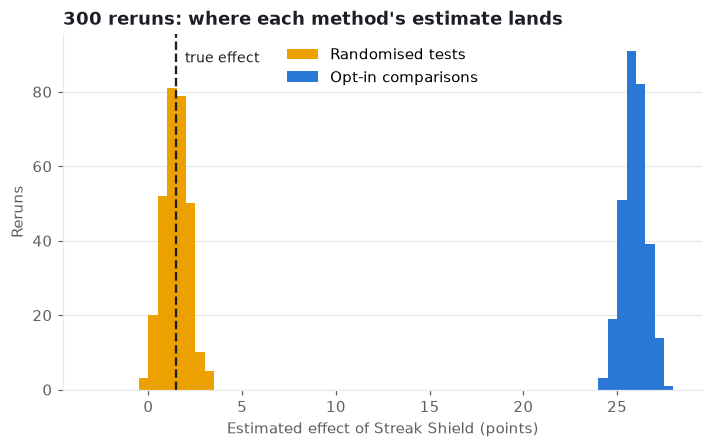

In [10]:
def estimate(df):
    t = df.shield == 1
    return 100 * (df.retained[t].mean() - df.retained[~t].mean())

rand_draws = np.array([estimate(F.randomise(L, seed=s)) for s in range(300)])
naive_draws = np.array([estimate(F.opt_in(L, seed=s)) for s in range(300)])

fig, ax = plt.subplots()
bins = np.linspace(-3, 28, 63)
ax.hist(rand_draws, bins=bins, color=style.SERIES[3], label="Randomised tests")
ax.hist(naive_draws, bins=bins, color=style.SERIES[0], label="Opt-in comparisons")
ax.axvline(100 * (L.y1 - L.y0).mean(), color=style.INK, linewidth=1.5, linestyle="--")
ax.annotate("true effect", xy=(100 * (L.y1 - L.y0).mean(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", fontsize=9, color=style.INK)
ax.set(title="300 reruns: where each method's estimate lands",
       xlabel="Estimated effect of Streak Shield (points)", ylabel="Reruns")
ax.legend(loc="upper center")
ax.grid(axis="x")
plt.show()

In [11]:
glue_num("rand_lo", np.percentile(rand_draws, 5))
glue_num("rand_hi", np.percentile(rand_draws, 95))
glue_num("naive_lo", np.floor(naive_draws.min()))
glue_num("naive_hi", np.ceil(naive_draws.max()))

The opt-in comparison is precise and wrong: every rerun lands between 24 and 28. The randomised tests are centred on the truth but spread out, with 90% of them between 0.3 and 2.5 points. Any single test is one draw from that spread.

That spread is the subject of the rest of Part I:

- **Chapter 2:** design the test so it's big enough to see an effect this size.
- **Chapter 3:** check that the coin flip actually happened the way you think.
- **Chapter 4:** read the result honestly, both frequentist and Bayesian.
- **Chapter 5:** shrink the spread with CUPED, which uses first-week lessons to cancel out noise. Peek at results without fooling yourself.
- **Chapter 6:** handle many metrics, many segments, and effects that change over time.

## Juno: the prompt that "won"

The same trap catches AI teams constantly. Juno's team wrote a new tutoring prompt, **v2**. To be careful, they rolled it out gradually, starting with vocabulary drills, where mistakes are cheap. A few weeks later:

In [12]:
J = F.juno_lessons(rollout="drills first")
J.groupby("prompt").completed.agg(lessons="size", completion_rate="mean").round(3)

,lessons,completion_rate
prompt,,
v1,13912,0.656
v2,16088,0.831


In [13]:
jg = J.groupby("prompt").completed.mean()
glue_num("juno_gap", 100 * (jg["v2"] - jg["v1"]))

v2 looks 18 points better. Now split by task:

In [14]:
J.pivot_table(index="task", columns="prompt", values="completed", aggfunc="mean").round(3)

prompt,v1,v2
task,,
Free conversation,0.466,0.472
Grammar explanation,0.720,0.718
Vocabulary drill,0.878,0.883


Within each kind of task, the two prompts are nearly identical. v2's "win" came from *where* it was deployed: mostly on easy drills, which almost always get completed. This is the same selection bias as Streak Shield, with task difficulty playing the part of keenness. A randomised rollout, where a coin picks the prompt for each lesson, gives the honest answer directly:

In [15]:
Jr = F.juno_lessons(rollout="random")
Jr.groupby("prompt").completed.agg(lessons="size", completion_rate="mean").round(3)

,lessons,completion_rate
prompt,,
v1,15005,0.749
v2,14995,0.751


Gradual rollouts are good engineering. Just don't *evaluate* a gradual rollout as if it were an experiment. If you want to compare prompts, models or agent versions, randomise within the traffic where both are allowed. Splitting by task, as above, helps only when you know and measured the thing that drove the rollout. Part III covers what to do when you can't randomise at all.

> **In the wild**
>
> For years, observational studies found that women who chose hormone therapy after menopause had less heart disease. Women who chose it also tended to be healthier and wealthier: a Streak Shield-style selection. When the Women's Health Initiative randomised it, the trial was stopped early in 2002 because estrogen plus progestin *increased* the risk of coronary heart disease, stroke and breast cancer (Rossouw et al., 2002). A coin flip reversed the conclusion of a generation of careful comparisons.

## Pitfalls

- **Comparing choosers with non-choosers.** Anything people opt into (features, settings, premium tiers) attracts different people. The difference you see is mostly the people.
- **Treating significance as causation.** A tiny p-value on a biased comparison is a precise measurement of the wrong thing.
- **Evaluating a staged rollout as an A/B test.** Whatever decided the rollout order (easy tasks first, friendly customers first) is now mixed into your result.
- **Quoting "observed power".** Pingouin's `power` column is computed from the effect you observed, so it just restates the p-value. Plan power from the effect you *want to detect*, before the test (Chapter 2).
- **Expecting big numbers.** Most real product changes move metrics by a point or two. If a result looks spectacular, look for selection first.

## Exercises

1. **No selection.** In `opt_in`, set the keenness coefficient from 1.6 to 0. What does the dashboard difference become? Why?
2. **Bigger test.** How many learners would the randomised test need for 80% power to detect the true effect? Try `pg.power_ttest`. (Chapter 2 does this properly.)
3. **Measured confounder.** In the opt-in data, compare retention within bands of `lessons_wk1` (say 0 to 2, 3 to 5, 6 and up). Does the gap shrink? Does it disappear? What does that tell you about adjusting for *observed* differences when keenness itself is hidden?

## Further reading

Wager (Wager, 2026) develops potential outcomes and the difference-in-means estimator carefully. Kohavi, Tang and Xu (Kohavi et al., 2020) collect many real examples of "lifts that weren't" from large online experiments.